In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


In [5]:

data = {
    'Registration': ['Yes', 'Yes', 'Yes', 'Yes',
                     'No', 'No', 'No', 'No'],

    'Reminder': ['Yes', 'Yes', 'No', 'No',
                 'Yes', 'Yes', 'No', 'No'],

    'Attended': ['Yes', 'Yes', 'Yes', 'No',
                 'No', 'No', 'No', 'No']
}

df = pd.DataFrame(data)

print(df)


  Registration Reminder Attended
0          Yes      Yes      Yes
1          Yes      Yes      Yes
2          Yes       No      Yes
3          Yes       No       No
4           No      Yes       No
5           No      Yes       No
6           No       No       No
7           No       No       No


In [7]:

X = df[['Registration', 'Reminder']]
y = df['Attended']

print("Features:")
print(X)

print("\nTarget:")
print(y)


Features:
  Registration Reminder
0          Yes      Yes
1          Yes      Yes
2          Yes       No
3          Yes       No
4           No      Yes
5           No      Yes
6           No       No
7           No       No

Target:
0    Yes
1    Yes
2    Yes
3     No
4     No
5     No
6     No
7     No
Name: Attended, dtype: object


In [11]:

X_encoded = X.apply(
    lambda col: col.map({'Yes': 1, 'No': 0})
).astype(int)

print(X_encoded)



   Registration  Reminder
0             1         1
1             1         1
2             1         0
3             1         0
4             0         1
5             0         1
6             0         0
7             0         0


In [13]:

counts = y.value_counts()

p_yes = counts['Yes'] / len(y)
p_no = counts['No'] / len(y)

root_gini = 1 - (p_yes**2 + p_no**2)

print("Total Records:", len(y))
print("Attended Yes:", counts['Yes'])
print("Attended No:", counts['No'])
print("Root Gini Impurity:", root_gini)


Total Records: 8
Attended Yes: 3
Attended No: 5
Root Gini Impurity: 0.46875


In [15]:

def calculate_gini(data):
    probabilities = data['Attended'].value_counts(normalize=True)
    return 1 - sum(probabilities**2)

for feature in X.columns:
    weighted_gini = 0

    for value in df[feature].unique():
        subset = df[df[feature] == value]

        gini = calculate_gini(subset)

        weighted_gini += (len(subset) / len(df)) * gini

        print(feature, "=", value, "Gini =", gini)

    print("Weighted Gini of", feature, "=", weighted_gini)
    print()


Registration = Yes Gini = 0.375
Registration = No Gini = 0.0
Weighted Gini of Registration = 0.1875

Reminder = Yes Gini = 0.5
Reminder = No Gini = 0.375
Weighted Gini of Reminder = 0.4375



In [17]:

model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=2,
    random_state=42
)

model.fit(X_encoded, y)

print("Decision Tree Training Completed")
print("Tree Depth:", model.get_depth())
print("Number of Leaves:", model.get_n_leaves())


Decision Tree Training Completed
Tree Depth: 2
Number of Leaves: 3


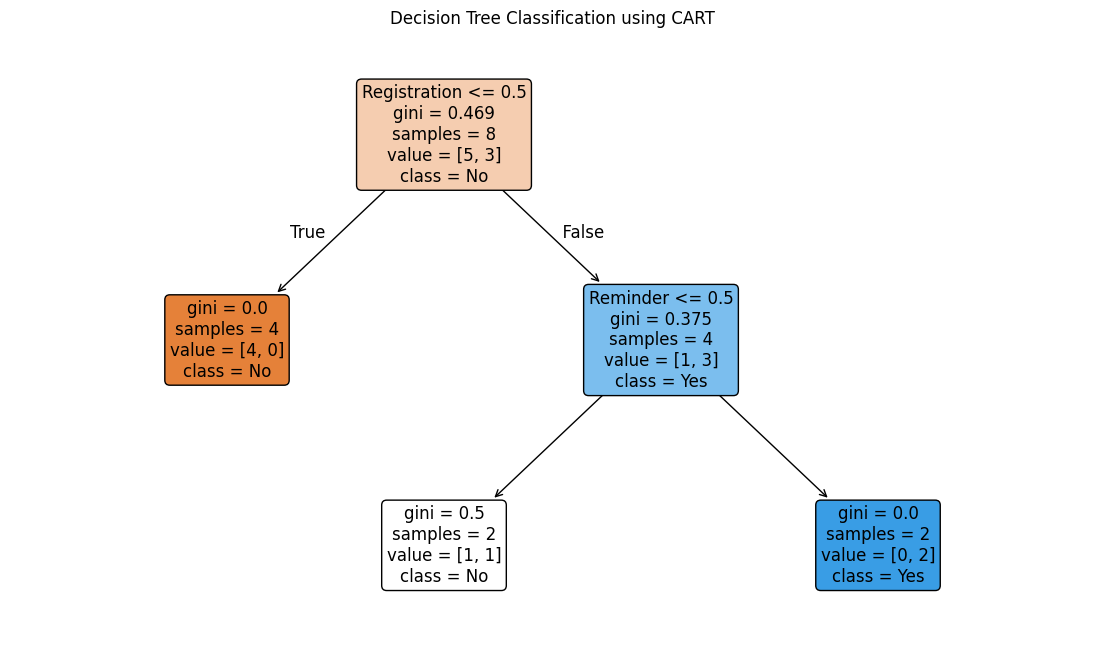

In [19]:

plt.figure(figsize=(14, 8))

plot_tree(
    model,
    feature_names=['Registration', 'Reminder'],
    class_names=model.classes_,
    filled=True,
    rounded=True,
    impurity=True,
    fontsize=12
)

plt.title("Decision Tree Classification using CART")
plt.show()


In [21]:

rules = export_text(
    model,
    feature_names=['Registration', 'Reminder']
)

print("Decision Tree Rules:")
print(rules)


Decision Tree Rules:
|--- Registration <= 0.50
|   |--- class: No
|--- Registration >  0.50
|   |--- Reminder <= 0.50
|   |   |--- class: No
|   |--- Reminder >  0.50
|   |   |--- class: Yes



In [23]:

y_pred = model.predict(X_encoded)

result = pd.DataFrame({
    'Actual': y,
    'Predicted': y_pred
})

print(result)


  Actual Predicted
0    Yes       Yes
1    Yes       Yes
2    Yes        No
3     No        No
4     No        No
5     No        No
6     No        No
7     No        No


In [25]:

accuracy = accuracy_score(y, y_pred)

print("Accuracy:", accuracy * 100, "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y, y_pred, labels=['No', 'Yes']))

print("\nClassification Report:")
print(classification_report(y, y_pred))


Accuracy: 87.5 %

Confusion Matrix:
[[5 0]
 [1 2]]

Classification Report:
              precision    recall  f1-score   support

          No       0.83      1.00      0.91         5
         Yes       1.00      0.67      0.80         3

    accuracy                           0.88         8
   macro avg       0.92      0.83      0.85         8
weighted avg       0.90      0.88      0.87         8



In [27]:

new_student = pd.DataFrame({
    'Registration': [1],
    'Reminder': [0]
})

prediction = model.predict(new_student)

print("Predicted Attendance:", prediction[0])


Predicted Attendance: No
